# Actividad 5 (Evaluación)

Ian Kaled Sandoval Gines | A01738687

In [1]:
#Cargamos librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.special as special
from scipy.optimize import curve_fit
import seaborn as sns
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

Para esta evaluación se trabaja con el archivo Datos_Complementarios_CLV.xlsx del socioformador. Primero se revisa qué hojas tiene el libro para decidir con cuál conviene trabajar.

In [2]:
#Revisamos las hojas que tiene el libro de Excel
libro = pd.ExcelFile('Datos_Complementarios_CLV.xlsx')
libro.sheet_names

['Existencias_15_10_2026', 'Histórico_Entradas_SAlidas', 'Histórico_Ventas']

El libro tiene tres hojas. Las de existencias y de entradas/salidas solo tienen una o dos columnas numéricas, así que no dan para mucho en una regresión. La hoja Histórico_Ventas tiene precio unitario, unidades y total neto, además de varias columnas categóricas (marca, estado, vendedor), por lo que es la que se usa en toda la actividad.

In [3]:
#Carga de la hoja de ventas desde el libro de Excel
df = pd.read_excel('Datos_Complementarios_CLV.xlsx', sheet_name='Histórico_Ventas')
df.head()

,folio_abreviado,folio,fecha_documento,articulo_id,nombre_articulo,marc,precio_unitario,total_unidades,total_neto,nombre_cliente,estado,ciudad,cp,vendedor
0,B00,B00013159,15.10.2026,16301346,AIZIR 98 X 14mm OM1,AIDITE,1310.35000,1,1310.35,ARTURO HERNANDEZ SF,Estado de México,Estado de Mexico,55140.0,DIEGO
1,CDF,CDF002643,15.10.2026,7214,"LUMEX DENTINE, A1, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD
2,CDF,CDF002643,15.10.2026,7217,"LUMEX DENTINE, A2, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD
3,CDF,CDF002643,15.10.2026,7223,"LUMEX DENTINE, A3, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD
4,CDF,CDF002643,15.10.2026,7277,"LUMEX ENAMEL, CLEAR, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD


In [4]:
#Verificamos información del DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21632 entries, 0 to 21631
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   folio_abreviado  21632 non-null  object 
 1   folio            21632 non-null  object 
 2   fecha_documento  21632 non-null  object 
 3   articulo_id      21632 non-null  int64  
 4   nombre_articulo  21632 non-null  object 
 5   marc             21632 non-null  object 
 6   precio_unitario  21632 non-null  float64
 7   total_unidades   21632 non-null  int64  
 8   total_neto       21632 non-null  float64
 9   nombre_cliente   21632 non-null  object 
 10  estado           21632 non-null  object 
 11  ciudad           21632 non-null  object 
 12  cp               21140 non-null  float64
 13  vendedor         21632 non-null  object 
dtypes: float64(3), int64(2), object(9)
memory usage: 2.3+ MB


## Preprocesamiento

### Transformaciones iniciales

Al revisar el info() se nota que la columna estado viene con espacios al final del nombre y que la columna de marca se llama marc. Se limpian los nombres de columna para no tener problemas más adelante.

In [5]:
#Quitamos los espacios de los nombres de columna y renombramos marc
df.columns = df.columns.str.strip()
df = df.rename(columns={'marc': 'marca'})
df.columns

Index(['folio_abreviado', 'folio', 'fecha_documento', 'articulo_id',
       'nombre_articulo', 'marca', 'precio_unitario', 'total_unidades',
       'total_neto', 'nombre_cliente', 'estado', 'ciudad', 'cp', 'vendedor'],
      dtype='object')

La columna estado tiene el mismo estado escrito de varias formas (por ejemplo "Ciudad de México" y "CIUDAD DE MÉXICO"), lo que la hace ver con más categorías de las que realmente tiene. Se pasa todo a mayúsculas y sin espacios para unificarlo.

In [6]:
#Unificamos la escritura de los estados
print("Estados antes:", df['estado'].nunique())
df['estado'] = df['estado'].str.strip().str.upper()
print("Estados después:", df['estado'].nunique())

Estados antes: 53
Estados después: 34


La fecha viene como texto con formato día.mes.año. Se convierte a fecha y de ahí se sacan el mes y el día como columnas numéricas, que después pueden servir para la regresión múltiple.

In [7]:
#Convertimos la fecha a tipo datetime y sacamos mes y día
df['fecha_documento'] = pd.to_datetime(df['fecha_documento'], format='%d.%m.%Y')
df['mes'] = df['fecha_documento'].dt.month
df['dia'] = df['fecha_documento'].dt.day
df.head()

,folio_abreviado,folio,fecha_documento,articulo_id,nombre_articulo,marca,precio_unitario,total_unidades,total_neto,nombre_cliente,estado,ciudad,cp,vendedor,mes,dia
0,B00,B00013159,2026-10-15,16301346,AIZIR 98 X 14mm OM1,AIDITE,1310.35000,1,1310.35,ARTURO HERNANDEZ SF,ESTADO DE MÉXICO,Estado de Mexico,55140.0,DIEGO,10,15
1,CDF,CDF002643,2026-10-15,7214,"LUMEX DENTINE, A1, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,CIUDAD DE MÉXICO,CDMX,4210.0,JAVIERCAD,10,15
2,CDF,CDF002643,2026-10-15,7217,"LUMEX DENTINE, A2, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,CIUDAD DE MÉXICO,CDMX,4210.0,JAVIERCAD,10,15
3,CDF,CDF002643,2026-10-15,7223,"LUMEX DENTINE, A3, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,CIUDAD DE MÉXICO,CDMX,4210.0,JAVIERCAD,10,15
4,CDF,CDF002643,2026-10-15,7277,"LUMEX ENAMEL, CLEAR, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,CIUDAD DE MÉXICO,CDMX,4210.0,JAVIERCAD,10,15


### Valores nulos

In [8]:
#Identificar valores nulos por columna
valores_nulos = df.isnull().sum()
valores_nulos

folio_abreviado      0
folio                0
fecha_documento      0
articulo_id          0
nombre_articulo      0
marca                0
precio_unitario      0
total_unidades       0
total_neto           0
nombre_cliente       0
estado               0
ciudad               0
cp                 492
vendedor             0
mes                  0
dia                  0
dtype: int64

La única columna con nulos es cp (código postal). Como es un dato del cliente y no un valor numérico que se promedie, se rellena con bfill y ffill, igual que se hizo en clase (el ffill es por si los últimos renglones también vienen vacíos).

In [9]:
#Sustituir valores nulos de cp con bfill y ffill
df['cp'] = df['cp'].bfill()
df['cp'] = df['cp'].ffill()

#Corroboramos valores nulos
valores_nulos = df.isnull().sum()
valores_nulos

folio_abreviado    0
folio              0
fecha_documento    0
articulo_id        0
nombre_articulo    0
marca              0
precio_unitario    0
total_unidades     0
total_neto         0
nombre_cliente     0
estado             0
ciudad             0
cp                 0
vendedor           0
mes                0
dia                0
dtype: int64

Aparte de los nulos, hay registros donde el precio unitario y el total neto valen cero. Son ventas sin importe (muestras, garantías o ajustes) y no aportan nada al modelo, al contrario, lo jalan hacia abajo. Se convierten en nulos y se sustituyen con la mediana, que es menos sensible a valores extremos que la media.

In [10]:
#Contamos cuántas ventas tienen precio y total en cero
print("Precio unitario en cero:", (df['precio_unitario'] == 0).sum())
print("Total neto en cero:", (df['total_neto'] == 0).sum())

Precio unitario en cero: 1612
Total neto en cero: 1612


In [11]:
#Convertimos los ceros en nulos y los sustituimos con la mediana
df['precio_unitario'] = df['precio_unitario'].replace(0, np.nan)
df['total_neto'] = df['total_neto'].replace(0, np.nan)

df['precio_unitario'] = df['precio_unitario'].fillna(round(df['precio_unitario'].median(), 2))
df['total_neto'] = df['total_neto'].fillna(round(df['total_neto'].median(), 2))

#Corroboramos valores nulos en todo el dataframe
valores_nulos = df.isnull().sum().sum()
valores_nulos

np.int64(0)

In [12]:
#Ya sin nulos, cp se deja como entero
df['cp'] = df['cp'].astype(int)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21632 entries, 0 to 21631
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   folio_abreviado  21632 non-null  object        
 1   folio            21632 non-null  object        
 2   fecha_documento  21632 non-null  datetime64[ns]
 3   articulo_id      21632 non-null  int64         
 4   nombre_articulo  21632 non-null  object        
 5   marca            21632 non-null  object        
 6   precio_unitario  21632 non-null  float64       
 7   total_unidades   21632 non-null  int64         
 8   total_neto       21632 non-null  float64       
 9   nombre_cliente   21632 non-null  object        
 10  estado           21632 non-null  object        
 11  ciudad           21632 non-null  object        
 12  cp               21632 non-null  int64         
 13  vendedor         21632 non-null  object        
 14  mes              21632 non-null  int32

### Valores atípicos

Se separan las variables cuantitativas de las cualitativas. Solo se revisan atípicos en precio_unitario, total_unidades y total_neto, que son las que miden algo. cp, mes y dia se quedan con las cualitativas porque son más bien identificadores y no tiene sentido buscarles valores extremos.

In [13]:
#Creo 2 dataframes para poder procesar los outliers
columnas_cuantitativas = ['precio_unitario', 'total_unidades', 'total_neto']
cuantitativas = df[columnas_cuantitativas]
cualitativas = df.drop(columns=columnas_cuantitativas)

<Figure size 1200x300 with 0 Axes>

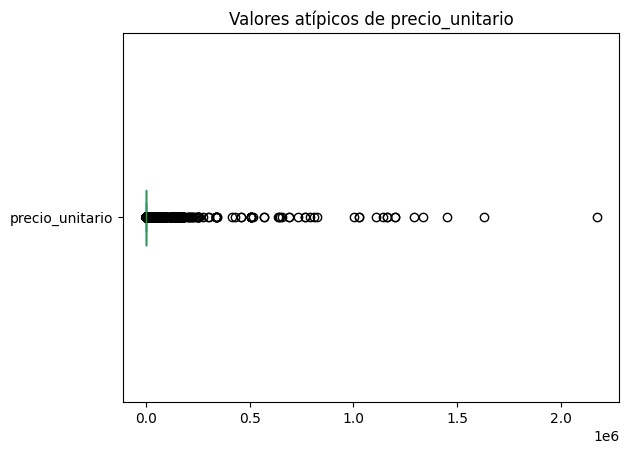

<Figure size 1200x300 with 0 Axes>

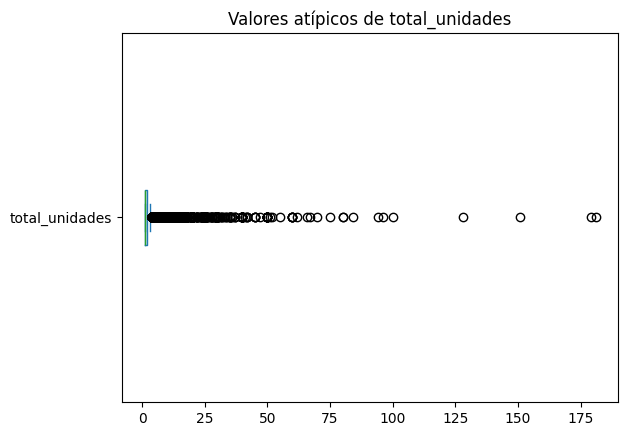

<Figure size 1200x300 with 0 Axes>

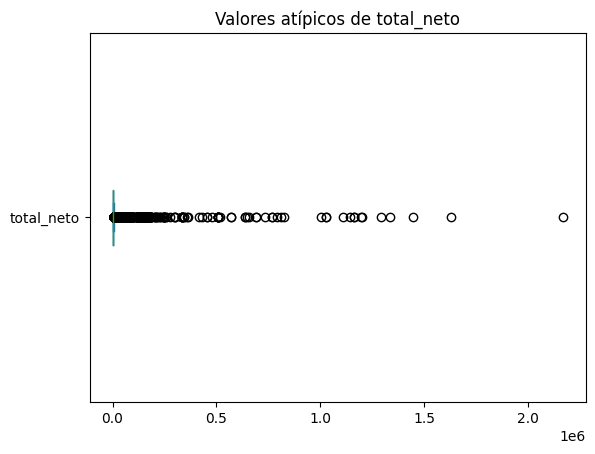

In [14]:
#Realizamos diagrama de caja de cada columna cuantitativa
for columna in columnas_cuantitativas:
    plt.figure(figsize=(12, 3))
    cuantitativas[[columna]].plot(kind='box', vert=False)
    plt.title("Valores atípicos de " + columna)
    plt.show()

Los diagramas muestran que las tres variables tienen valores muy alejados del resto (ventas de más de un millón de pesos cuando la mediana ronda los mil). Se aplican los dos métodos vistos en clase.

Método de desviación estándar

In [15]:
#Método aplicando desviación estandar. Encuentro los valores extremos
y = cuantitativas
Limite_Superior = y.mean() + 3*y.std()
Limite_Inferior = y.mean() - 3*y.std()
print("Limite superior permitido")
print(Limite_Superior)
print("Limite inferior permitido")
print(Limite_Inferior)

Limite superior permitido
precio_unitario    132894.627537
total_unidades         18.622250
total_neto         134956.696032
dtype: float64
Limite inferior permitido
precio_unitario   -124101.201522
total_unidades        -13.036359
total_neto        -124010.785466
dtype: float64


In [16]:
#Obtenemos datos y los outliers se convierten en nulos en el DataFrame
cuantitativas_std = cuantitativas[(y <= Limite_Superior) & (y >= Limite_Inferior)]

#Corroboramos cuántos atípicos encontró cada columna
valores_nulos_std = cuantitativas_std.isnull().sum()
valores_nulos_std

precio_unitario    147
total_unidades     445
total_neto         149
dtype: int64

In [17]:
#Reemplazamos valores atípicos (nulos) del dataframe con la media
cuantitativas_std_limpias = cuantitativas_std.fillna(round(cuantitativas_std.mean(), 2))

#Corroboramos valores nulos
cuantitativas_std_limpias.isnull().sum()

precio_unitario    0
total_unidades     0
total_neto         0
dtype: int64

Método de rango intercuartílico

In [18]:
#Método aplicando Cuartiles. Encuentro cuartiles 0.25 y 0.75
y = cuantitativas
percentile25 = y.quantile(0.25) #Q1
percentile75 = y.quantile(0.75) #Q3
iqr = percentile75 - percentile25

Limite_Superior_iqr = percentile75 + 1.5*iqr
Limite_Inferior_iqr = percentile25 - 1.5*iqr
print("Limite superior permitido")
print(Limite_Superior_iqr)
print("Limite inferior permitido")
print(Limite_Inferior_iqr)

Limite superior permitido
precio_unitario    2952.579311
total_unidades        3.500000
total_neto         4853.998750
dtype: float64
Limite inferior permitido
precio_unitario   -1495.685518
total_unidades       -0.500000
total_neto        -2360.671250
dtype: float64


In [19]:
#Obtenemos datos y los outliers se convierten en nulos
cuantitativas_iqr = cuantitativas[(y <= Limite_Superior_iqr) & (y >= Limite_Inferior_iqr)]

#Corroboramos cuántos atípicos encontró cada columna
valores_nulos_iqr = cuantitativas_iqr.isnull().sum()
valores_nulos_iqr

precio_unitario    1076
total_unidades     3659
total_neto         2225
dtype: int64

In [20]:
#Reemplazamos valores atípicos (nulos) del dataframe con la mediana
cuantitativas_iqr_limpias = cuantitativas_iqr.fillna(round(cuantitativas_iqr.median(), 2))

#Corroboramos valores nulos
cuantitativas_iqr_limpias.isnull().sum()

precio_unitario    0
total_unidades     0
total_neto         0
dtype: int64

Comparación de los dos métodos

El rango intercuartílico es mucho más estricto: marca como atípica cualquier venta de más de 2 unidades y cualquier total arriba de unos 5 mil pesos, con lo que sustituye miles de registros y deja casi todas las unidades en 1. Eso aplana la relación entre las variables. La desviación estándar solo quita las ventas realmente extremas (unas cuantas centenas), así que para modelar se usa el dataframe limpiado con desviación estándar.

In [21]:
#Comparamos cuántos registros modificó cada método
comparacion = pd.DataFrame({
    'Atipicos desviacion estandar': valores_nulos_std,
    'Atipicos rango intercuartilico': valores_nulos_iqr
})
comparacion

,Atipicos desviacion estandar,Atipicos rango intercuartilico
precio_unitario,147,1076
total_unidades,445,3659
total_neto,149,2225


In [22]:
#Unimos el dataframe cuantitativo limpio con el dataframe cualitativo
Datos_limpios = pd.concat([cualitativas, cuantitativas_std_limpias], axis=1)
Datos_limpios.head()

,folio_abreviado,folio,fecha_documento,articulo_id,nombre_articulo,marca,nombre_cliente,estado,ciudad,cp,vendedor,mes,dia,precio_unitario,total_unidades,total_neto
0,B00,B00013159,2026-10-15,16301346,AIZIR 98 X 14mm OM1,AIDITE,ARTURO HERNANDEZ SF,ESTADO DE MÉXICO,Estado de Mexico,55140,DIEGO,10,15,1310.35000,1.0,1310.35
1,CDF,CDF002643,2026-10-15,7214,"LUMEX DENTINE, A1, 12 G",VITA,ROBERTO CUEVAS DE LOS COBOS,CIUDAD DE MÉXICO,CDMX,4210,JAVIERCAD,10,15,508.62069,1.0,508.62
2,CDF,CDF002643,2026-10-15,7217,"LUMEX DENTINE, A2, 12 G",VITA,ROBERTO CUEVAS DE LOS COBOS,CIUDAD DE MÉXICO,CDMX,4210,JAVIERCAD,10,15,508.62069,1.0,508.62
3,CDF,CDF002643,2026-10-15,7223,"LUMEX DENTINE, A3, 12 G",VITA,ROBERTO CUEVAS DE LOS COBOS,CIUDAD DE MÉXICO,CDMX,4210,JAVIERCAD,10,15,508.62069,1.0,508.62
4,CDF,CDF002643,2026-10-15,7277,"LUMEX ENAMEL, CLEAR, 12 G",VITA,ROBERTO CUEVAS DE LOS COBOS,CIUDAD DE MÉXICO,CDMX,4210,JAVIERCAD,10,15,508.62069,1.0,508.62


<Figure size 1200x300 with 0 Axes>

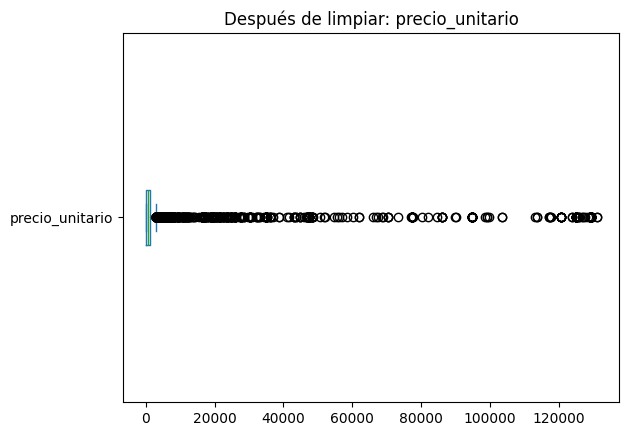

<Figure size 1200x300 with 0 Axes>

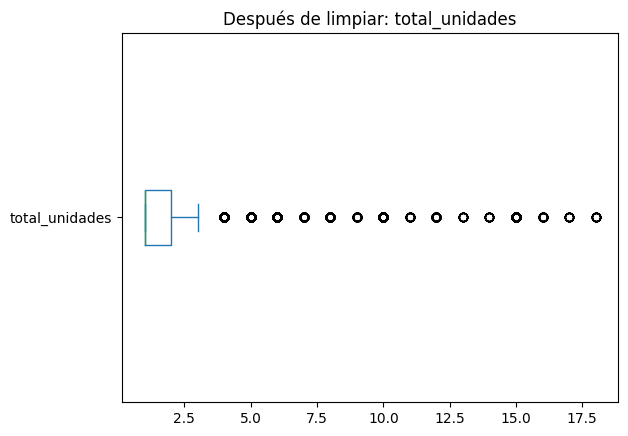

<Figure size 1200x300 with 0 Axes>

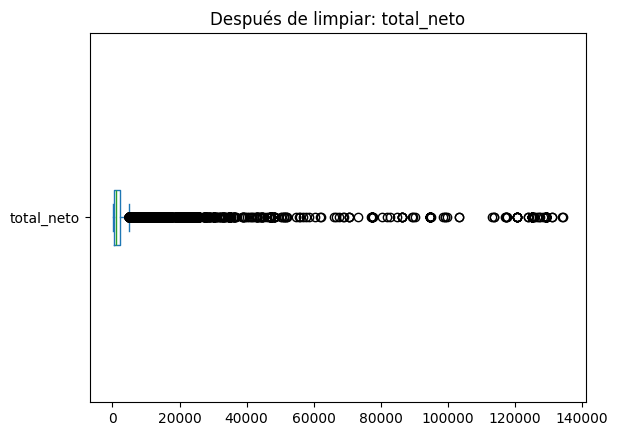

In [23]:
#Diagramas de caja después de limpiar los atípicos
for columna in columnas_cuantitativas:
    plt.figure(figsize=(12, 3))
    Datos_limpios[[columna]].plot(kind='box', vert=False)
    plt.title("Después de limpiar: " + columna)
    plt.show()

In [24]:
#Verificamos dimensiones y nulos del dataframe final
print("Dimensiones de Datos_limpios:", Datos_limpios.shape)
print("Valores nulos de Datos_limpios:", Datos_limpios.isnull().sum().sum())

#Convertir DataFrame a CSV
Datos_limpios.to_csv("Ventas_CLV_limpio.csv", index=False)

Dimensiones de Datos_limpios: (21632, 16)
Valores nulos de Datos_limpios: 0


## Regresión lineal simple

### Correlación entre las variables

Se toman las columnas numéricas del dataframe limpio y se revisa la relación entre todas ellas con un pairplot, la matriz de correlación y un mapa de calor.

In [25]:
#Nos quedamos solo con las columnas numéricas
numericas = Datos_limpios[['precio_unitario', 'total_unidades', 'total_neto', 'cp', 'mes', 'dia']]
numericas.head()

,precio_unitario,total_unidades,total_neto,cp,mes,dia
0,1310.35000,1.0,1310.35,55140,10,15
1,508.62069,1.0,508.62,4210,10,15
2,508.62069,1.0,508.62,4210,10,15
3,508.62069,1.0,508.62,4210,10,15
4,508.62069,1.0,508.62,4210,10,15


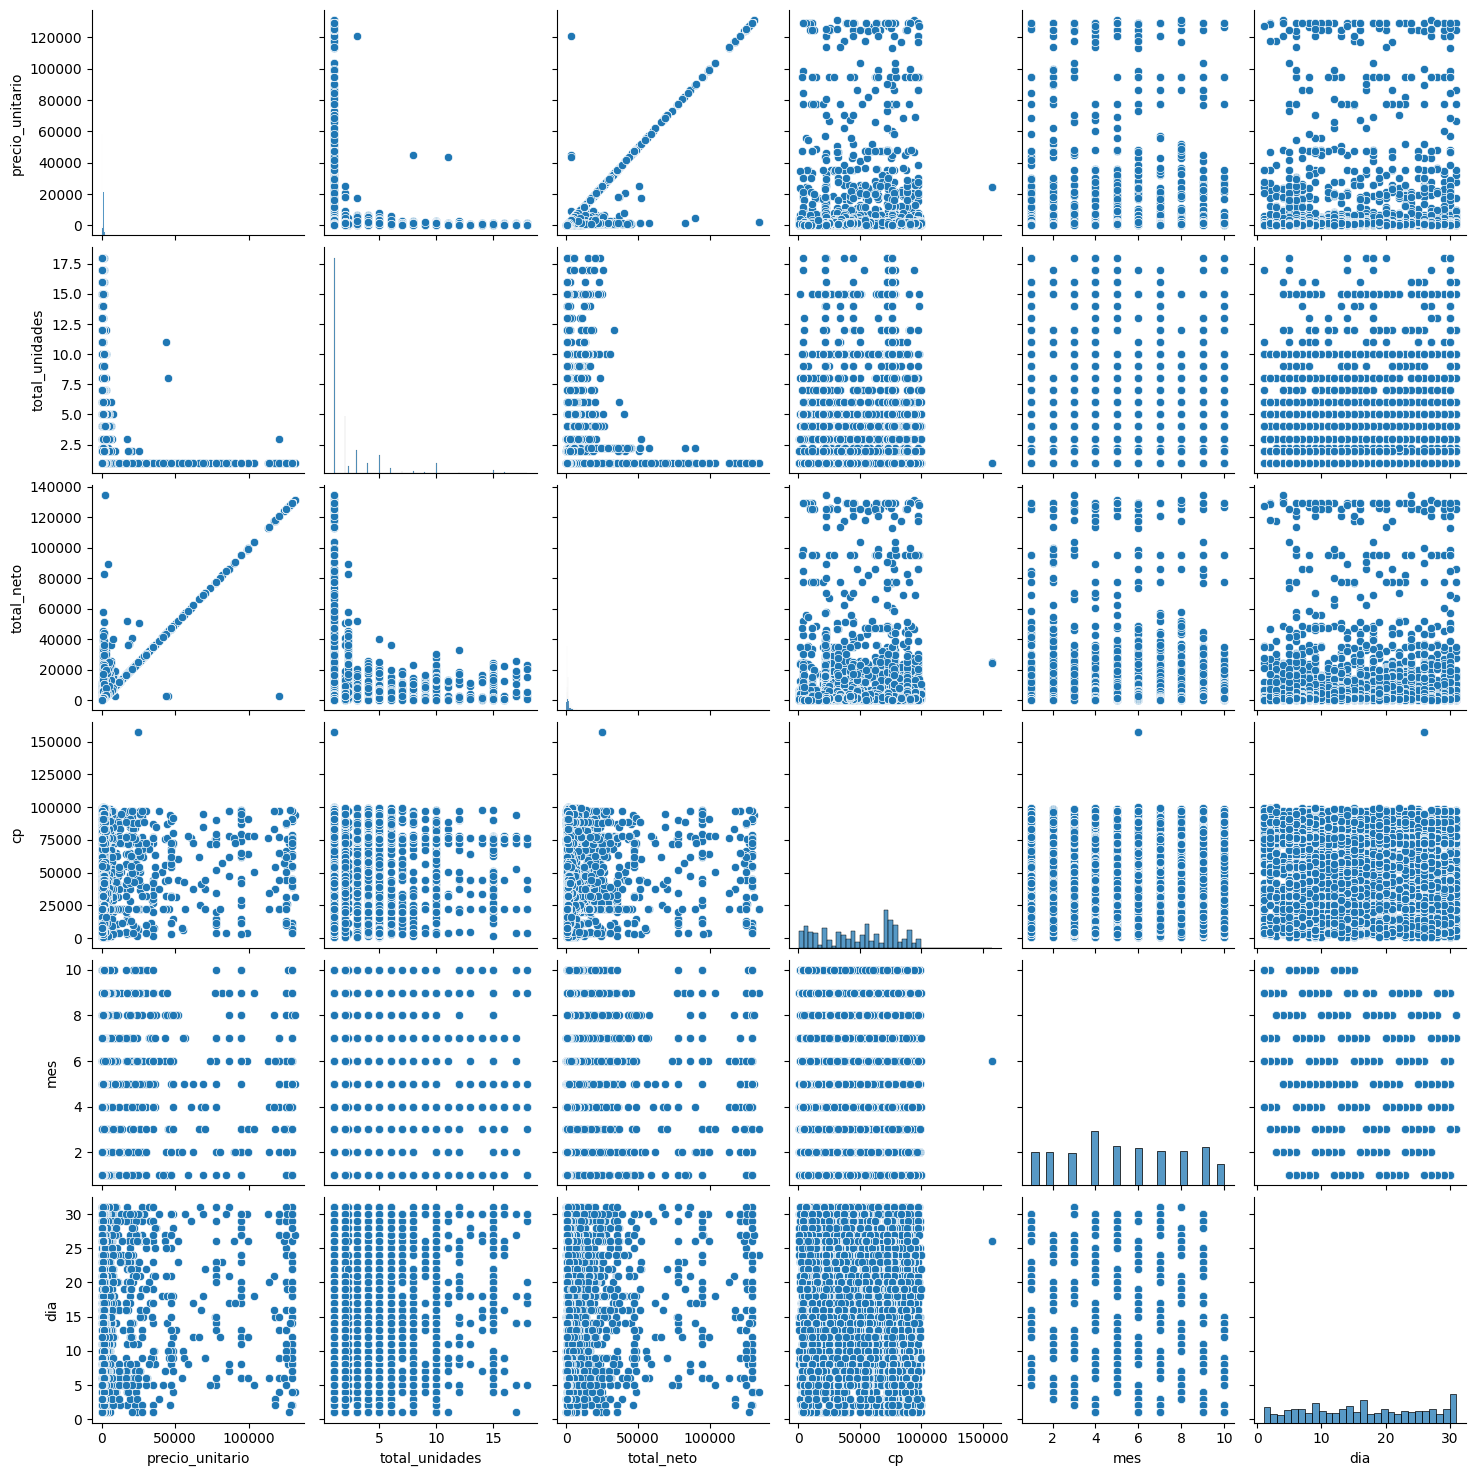

In [26]:
#Graficamos todas las dispersiones entre todas las variables
sns.pairplot(numericas)

In [27]:
#Encontramos todas las correlaciones entre las variables
Corr_Factors = numericas.corr()
Corr_Factors

,precio_unitario,total_unidades,total_neto,cp,mes,dia
precio_unitario,1.000000,-0.062082,0.943519,0.017944,-0.015507,0.004584
total_unidades,-0.062082,1.000000,0.058213,0.023381,-0.034542,0.050684
total_neto,0.943519,0.058213,1.000000,0.005331,-0.014094,0.006028
cp,0.017944,0.023381,0.005331,1.000000,-0.022844,0.029176
mes,-0.015507,-0.034542,-0.014094,-0.022844,1.000000,-0.145164
dia,0.004584,0.050684,0.006028,0.029176,-0.145164,1.000000


In [28]:
#Encontramos el valor absoluto de todas las correlaciones entre las variables
Corr_Factors1 = abs(Corr_Factors)
Corr_Factors1

,precio_unitario,total_unidades,total_neto,cp,mes,dia
precio_unitario,1.000000,0.062082,0.943519,0.017944,0.015507,0.004584
total_unidades,0.062082,1.000000,0.058213,0.023381,0.034542,0.050684
total_neto,0.943519,0.058213,1.000000,0.005331,0.014094,0.006028
cp,0.017944,0.023381,0.005331,1.000000,0.022844,0.029176
mes,0.015507,0.034542,0.014094,0.022844,1.000000,0.145164
dia,0.004584,0.050684,0.006028,0.029176,0.145164,1.000000


<Axes: >

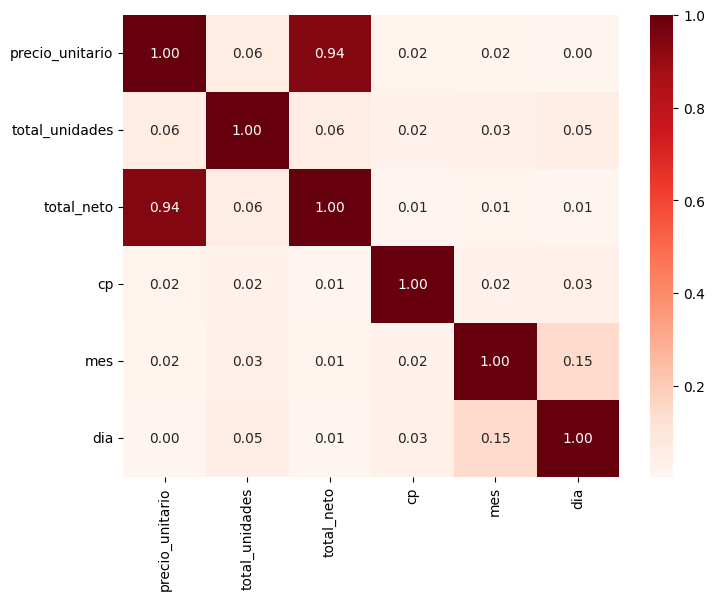

In [29]:
#Graficamos el mapa de calor de los coeficientes de correlación
plt.figure(figsize=(8, 6))
Heat_Map = sns.heatmap(Corr_Factors1, cmap='Reds', annot=True, fmt=".2f")
Heat_Map

La correlación más alta de toda la base es entre precio_unitario y total_neto, con un valor cercano a 0.94. Tiene sentido: el total de la venta es básicamente el precio por las unidades, y como la mayoría de las ventas son de una sola unidad, el precio casi determina el total. Las demás variables (cp, mes, dia) prácticamente no se relacionan con nada, con correlaciones menores a 0.05. Por eso el modelo simple se arma con total_neto como variable dependiente y precio_unitario como independiente.

<Axes: xlabel='precio_unitario', ylabel='total_neto'>

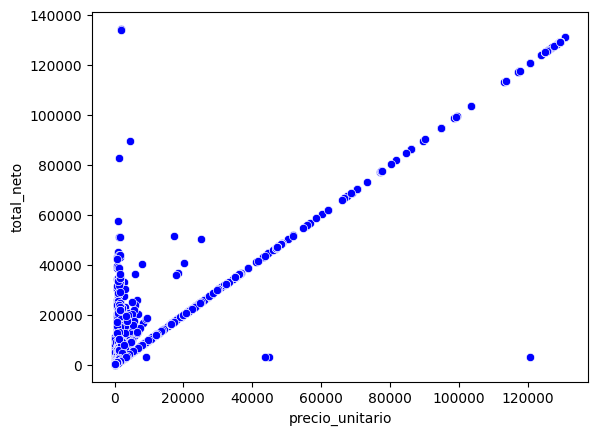

In [30]:
#Imprimimos el scatter plot entre la variable dependiente (total_neto) e independiente (precio_unitario)
#para observar el comportamiento en su dispersión
sns.scatterplot(x='precio_unitario', y='total_neto', color="blue", data=Datos_limpios)

### Modelo de regresión lineal simple

In [31]:
#Declaramos las variables dependientes e independientes para la regresión lineal
Vars_Indep = Datos_limpios[['precio_unitario']]
Var_Dep = Datos_limpios['total_neto']

In [32]:
#Se define model como la función de regresión lineal
from sklearn.linear_model import LinearRegression
model = LinearRegression()

In [33]:
#Ajustamos el modelo con las variables antes declaradas
model.fit(X=Vars_Indep, y=Var_Dep)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [34]:
#Verificamos los coeficientes obtenidos para el modelo ajustado
model.__dict__

{'fit_intercept': True,
 'copy_X': True,
 'tol': 1e-06,
 'n_jobs': None,
 'positive': False,
 'feature_names_in_': array(['precio_unitario'], dtype=object),
 'n_features_in_': 1,
 'coef_': array([0.98489506]),
 'rank_': 1,
 'singular_': array([1444696.82725295]),
 'intercept_': np.float64(1055.507449461103)}

In [35]:
#Armamos la ecuación del modelo
print("total_neto =", model.coef_[0], "* precio_unitario +", model.intercept_)

total_neto = 0.9848950572995678 * precio_unitario + 1055.507449461103


Modelo matemático: total_neto = 0.9849(precio_unitario) + 1055.51

In [36]:
#Evaluamos la eficiencia del modelo obtenido por medio del coeficiente R Determinación
coef_Deter = model.score(X=Vars_Indep, y=Var_Dep)
coef_Deter

0.8902283537094933

In [37]:
#Corroboramos cual es el coeficiente de Correlación de nuestro modelo
coef_Correl = np.sqrt(coef_Deter)
coef_Correl

np.float64(0.9435191326674268)

In [38]:
#Predecimos los valores de total_neto a partir de la variable precio_unitario
y_pred = model.predict(X=Datos_limpios[['precio_unitario']])
y_pred

array([2346.06468779, 1556.44545308, 1556.44545308, ..., 1225.32305524,
       1225.32305524, 1225.31320629], shape=(21632,))

In [39]:
#Insertamos la columna de predicciones en el DataFrame
Datos_limpios.insert(0, 'Predicciones', y_pred)
Datos_limpios.head()

,Predicciones,folio_abreviado,folio,fecha_documento,articulo_id,nombre_articulo,marca,nombre_cliente,estado,ciudad,cp,vendedor,mes,dia,precio_unitario,total_unidades,total_neto
0,2346.064688,B00,B00013159,2026-10-15,16301346,AIZIR 98 X 14mm OM1,AIDITE,ARTURO HERNANDEZ SF,ESTADO DE MÉXICO,Estado de Mexico,55140,DIEGO,10,15,1310.35000,1.0,1310.35
1,1556.445453,CDF,CDF002643,2026-10-15,7214,"LUMEX DENTINE, A1, 12 G",VITA,ROBERTO CUEVAS DE LOS COBOS,CIUDAD DE MÉXICO,CDMX,4210,JAVIERCAD,10,15,508.62069,1.0,508.62
2,1556.445453,CDF,CDF002643,2026-10-15,7217,"LUMEX DENTINE, A2, 12 G",VITA,ROBERTO CUEVAS DE LOS COBOS,CIUDAD DE MÉXICO,CDMX,4210,JAVIERCAD,10,15,508.62069,1.0,508.62
3,1556.445453,CDF,CDF002643,2026-10-15,7223,"LUMEX DENTINE, A3, 12 G",VITA,ROBERTO CUEVAS DE LOS COBOS,CIUDAD DE MÉXICO,CDMX,4210,JAVIERCAD,10,15,508.62069,1.0,508.62
4,1556.445453,CDF,CDF002643,2026-10-15,7277,"LUMEX ENAMEL, CLEAR, 12 G",VITA,ROBERTO CUEVAS DE LOS COBOS,CIUDAD DE MÉXICO,CDMX,4210,JAVIERCAD,10,15,508.62069,1.0,508.62


<Axes: xlabel='precio_unitario', ylabel='total_neto'>

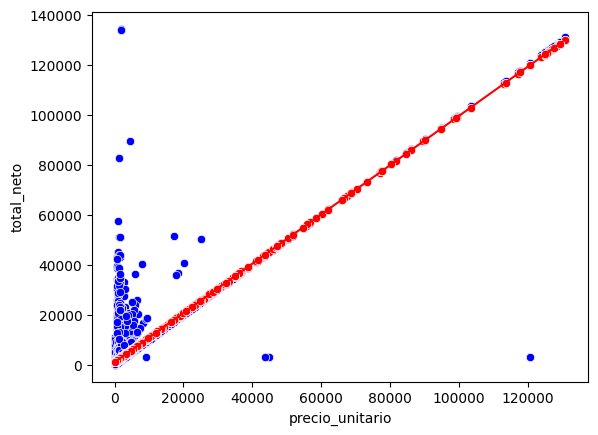

In [40]:
#Visualizamos la gráfica comparativa entre el total real y el total predecido
sns.scatterplot(x='precio_unitario', y='total_neto', color="blue", data=Datos_limpios)
sns.scatterplot(x='precio_unitario', y='Predicciones', color="red", data=Datos_limpios)
sns.lineplot(x='precio_unitario', y='Predicciones', color="red", data=Datos_limpios)

El modelo simple obtiene un coeficiente de determinación R² de 0.89 y un coeficiente de correlación de 0.94. Es decir, el precio unitario explica alrededor del 89% de la variación del total neto. En la gráfica se ve que la línea roja sigue bien la nube de puntos, aunque hay ventas que quedan muy por arriba de la línea: son las de varias unidades, donde el precio solo ya no alcanza para explicar el total.

## Regresión lineal múltiple

Ahora se intenta explicar total_neto con más de una variable. Lo lógico es que el total dependa del precio y de las unidades, pero también se prueban mes, dia y cp para ver si aportan algo. Se ajustan varios modelos y se compara su R² para quedarse con el mejor.

In [41]:
#Probamos distintas combinaciones de variables independientes
combinaciones = {
    'precio + unidades': ['precio_unitario', 'total_unidades'],
    'precio + unidades + mes': ['precio_unitario', 'total_unidades', 'mes'],
    'precio + unidades + mes + dia': ['precio_unitario', 'total_unidades', 'mes', 'dia'],
    'todas': ['precio_unitario', 'total_unidades', 'mes', 'dia', 'cp']
}

for nombre, columnas in combinaciones.items():
    modelo_prueba = LinearRegression()
    modelo_prueba.fit(X=Datos_limpios[columnas], y=Datos_limpios['total_neto'])
    print(nombre, "-> R2 =", round(modelo_prueba.score(Datos_limpios[columnas], Datos_limpios['total_neto']), 4))

precio + unidades -> R2 = 0.9039
precio + unidades + mes -> R2 = 0.9039
precio + unidades + mes + dia -> R2 = 0.904
todas -> R2 = 0.9042


Agregar mes, dia y cp casi no mueve el R² (pasa de 0.9039 a 0.9042), así que no vale la pena complicar el modelo con variables que no aportan. El mejor modelo múltiple se queda con precio_unitario y total_unidades.

In [42]:
#Declaramos las variables dependientes e independientes para la regresión lineal múltiple
Vars_Indep_m = Datos_limpios[['precio_unitario', 'total_unidades']]
Var_Dep_m = Datos_limpios['total_neto']

In [43]:
#Se define model_m como la función de regresión lineal múltiple
model_m = LinearRegression()

#Ajustamos el modelo con las variables antes declaradas
model_m.fit(X=Vars_Indep_m, y=Var_Dep_m)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [44]:
#Verificamos los coeficientes obtenidos para el modelo ajustado
model_m.__dict__

{'fit_intercept': True,
 'copy_X': True,
 'tol': 1e-06,
 'n_jobs': None,
 'positive': False,
 'feature_names_in_': array(['precio_unitario', 'total_unidades'], dtype=object),
 'n_features_in_': 2,
 'coef_': array([  0.9924928 , 484.86953405]),
 'rank_': 2,
 'singular_': array([1.44469683e+06, 3.63940038e+02]),
 'intercept_': np.float64(-36.91967382258463)}

In [45]:
#Armamos la ecuación del modelo
print("total_neto =", model_m.coef_[0], "* precio_unitario +", model_m.coef_[1], "* total_unidades +", model_m.intercept_)

total_neto = 0.9924928018455826 * precio_unitario + 484.8695340542321 * total_unidades + -36.91967382258463


Modelo matemático: total_neto = 0.9925(precio_unitario) + 484.87(total_unidades) - 36.92

In [46]:
#Evaluamos la eficiencia del modelo obtenido por medio del coeficiente R Determinación
coef_Deter_m = model_m.score(X=Vars_Indep_m, y=Var_Dep_m)
coef_Deter_m

0.9039206892717127

In [47]:
#Corroboramos cual es el coeficiente de Correlación de nuestro modelo
coef_Correl_m = np.sqrt(coef_Deter_m)
coef_Correl_m

np.float64(0.9507474371628423)

In [48]:
#Predecimos los valores de total_neto a partir de precio_unitario y total_unidades
y_pred_m = model_m.predict(X=Datos_limpios[['precio_unitario', 'total_unidades']])

#Insertamos la columna de predicciones en el DataFrame
Datos_limpios.insert(1, 'Predicciones_multiple', y_pred_m)
Datos_limpios.head()

,Predicciones,Predicciones_multiple,folio_abreviado,folio,fecha_documento,articulo_id,nombre_articulo,marca,nombre_cliente,estado,ciudad,cp,vendedor,mes,dia,precio_unitario,total_unidades,total_neto
0,2346.064688,1748.462803,B00,B00013159,2026-10-15,16301346,AIZIR 98 X 14mm OM1,AIDITE,ARTURO HERNANDEZ SF,ESTADO DE MÉXICO,Estado de Mexico,55140,DIEGO,10,15,1310.35000,1.0,1310.35
1,1556.445453,952.752234,CDF,CDF002643,2026-10-15,7214,"LUMEX DENTINE, A1, 12 G",VITA,ROBERTO CUEVAS DE LOS COBOS,CIUDAD DE MÉXICO,CDMX,4210,JAVIERCAD,10,15,508.62069,1.0,508.62
2,1556.445453,952.752234,CDF,CDF002643,2026-10-15,7217,"LUMEX DENTINE, A2, 12 G",VITA,ROBERTO CUEVAS DE LOS COBOS,CIUDAD DE MÉXICO,CDMX,4210,JAVIERCAD,10,15,508.62069,1.0,508.62
3,1556.445453,952.752234,CDF,CDF002643,2026-10-15,7223,"LUMEX DENTINE, A3, 12 G",VITA,ROBERTO CUEVAS DE LOS COBOS,CIUDAD DE MÉXICO,CDMX,4210,JAVIERCAD,10,15,508.62069,1.0,508.62
4,1556.445453,952.752234,CDF,CDF002643,2026-10-15,7277,"LUMEX ENAMEL, CLEAR, 12 G",VITA,ROBERTO CUEVAS DE LOS COBOS,CIUDAD DE MÉXICO,CDMX,4210,JAVIERCAD,10,15,508.62069,1.0,508.62


<Axes: xlabel='precio_unitario', ylabel='total_neto'>

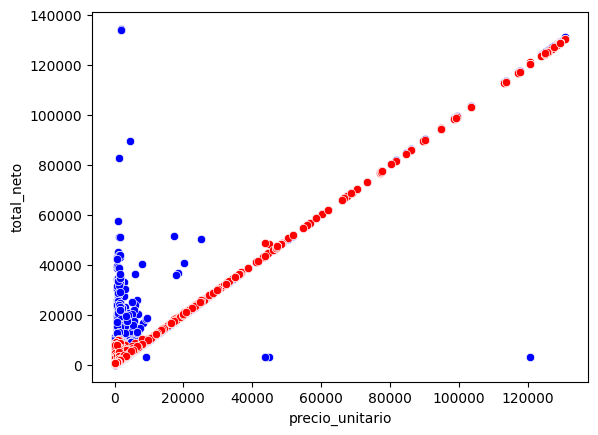

In [49]:
#Visualizamos la gráfica comparativa entre el total real y el total predecido
sns.scatterplot(x='precio_unitario', y='total_neto', color="blue", data=Datos_limpios)
sns.scatterplot(x='precio_unitario', y='Predicciones_multiple', color="red", data=Datos_limpios)

### Comparación de coeficientes: modelo simple vs modelo múltiple

In [50]:
#Comparamos los coeficientes y la eficiencia de los dos modelos
comparacion_modelos = pd.DataFrame({
    'Regresion simple': [model.coef_[0], np.nan, model.intercept_, coef_Deter, coef_Correl],
    'Regresion multiple': [model_m.coef_[0], model_m.coef_[1], model_m.intercept_, coef_Deter_m, coef_Correl_m]
}, index=['Coef. precio_unitario', 'Coef. total_unidades', 'Intercepto', 'R2 (determinacion)', 'r (correlacion)'])
comparacion_modelos

,Regresion simple,Regresion multiple
Coef. precio_unitario,0.984895,0.992493
Coef. total_unidades,NaN,484.869534
Intercepto,1055.507449,-36.919674
R2 (determinacion),0.890228,0.903921
r (correlacion),0.943519,0.950747


Al comparar los dos modelos se observa lo siguiente:

- El coeficiente de precio_unitario casi no cambia (0.985 en el simple contra 0.992 en el múltiple). En los dos casos cada peso de precio se refleja casi en un peso de total, lo cual es lógico.
- El intercepto sí cambia bastante: en el modelo simple es de 1055.51 y en el múltiple baja a -36.92. En el simple el intercepto estaba absorbiendo el efecto de las unidades que no se incluían; al agregar total_unidades, ese efecto pasa a su propio coeficiente (484.87 pesos por unidad extra) y el intercepto se acerca a cero, que es lo que uno esperaría de una venta de cero unidades.
- El R² sube de 0.890 a 0.904 y la correlación de 0.944 a 0.951. La mejora es pequeña pero real, porque la segunda variable explica precisamente las ventas de varias unidades que el modelo simple no alcanzaba.

En resumen, el modelo múltiple es un poco mejor y además tiene coeficientes más fáciles de interpretar.

## Regresión logística

### Variable dicotómica: estado

Para la regresión logística se necesita una variable con solo dos categorías. La columna estado tiene muchos estados, así que se convierte en dicotómica: Ciudad de México contra todo lo demás. Es una buena variable porque está desbalanceada (la CDMX es como el 20% de las ventas), que es justo donde hacen falta la reponderación de clases y el oversampling.

In [51]:
#Analizar categorias de la columna estado
Categorias = Datos_limpios.groupby(['estado'])['estado'].count()
Categorias

estado
AGUASCALIENTES          413
BAJA CALIFORNIA         741
BAJA CALIFORNIA SUR       7
CAMPECHE                  4
CHIAPAS                 100
CHIHUAHUA               544
CIUDAD DE MÉXICO       4315
COAHUILA                456
COLIMA                    9
DURANGO                 343
ESTADO DE MÉXICO       2361
GUANAJUATO              779
GUERRERO                218
HIDALGO                 369
JALISCO                1147
MICHOACÁN               341
MORELOS                 308
MÉXICO                    4
NAYARIT                 196
NUEVO LEÓN              418
OAXACA                  249
PUEBLA                 2829
QUERÉTARO              1351
QUINTANA ROO            615
SAN LUIS POTOSÍ         463
SIN ESTADO              138
SINALOA                 156
SONORA                  395
TABASCO                 180
TAMAULIPAS              611
TLAXCALA                305
VERACRUZ                579
YUCATÁN                 586
ZACATECAS               102
Name: estado, dtype: int64

In [52]:
#Convertimos la columna estado en una variable dicotómica
Datos_limpios['estado_dicotomica'] = np.where(Datos_limpios['estado'] == 'CIUDAD DE MÉXICO', 'CDMX', 'Otro estado')

#Analizar categorias de la nueva columna
Categorias = Datos_limpios.groupby(['estado_dicotomica'])['estado_dicotomica'].count()
Categorias

estado_dicotomica
CDMX            4315
Otro estado    17317
Name: estado_dicotomica, dtype: int64

In [53]:
#Declaramos las variables dependientes e independientes para la regresión Logística
Vars_Indep = Datos_limpios[['precio_unitario', 'total_unidades', 'total_neto']]
Var_Dep = Datos_limpios['estado_dicotomica']

In [54]:
#Redefinimos las variables
X = Vars_Indep
y = Var_Dep

In [55]:
#Dividimos el conjunto de datos en la parte de entrenamiento y prueba
#random_state fijo para que los resultados no cambien cada vez que se corre
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

In [56]:
#Se escalan todos los datos
escalar = StandardScaler()

#Para realizar el escalamiento de las variables "X" tanto de entrenamiento como de prueba, utilizaremos fit_transform
X_train = escalar.fit_transform(X_train)
X_test = escalar.transform(X_test)

In [57]:
#Definimos el algoritmo a utilizar
from sklearn.linear_model import LogisticRegression
algoritmo = LogisticRegression()

#Entrenamos el modelo
algoritmo.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [58]:
#Realizamos una predicción
y_pred = algoritmo.predict(X_test)
y_pred

array(['Otro estado', 'Otro estado', 'Otro estado', ..., 'Otro estado',
       'Otro estado', 'Otro estado'], shape=(6490,), dtype=object)

In [59]:
#Verifico la matriz de Confusión
from sklearn.metrics import confusion_matrix
matriz = confusion_matrix(y_test, y_pred)
print('Matriz de Confusión:')
print(matriz)

Matriz de Confusión:
[[   0 1319]
 [   1 5170]]


In [60]:
#Calculo la precisión, exactitud, sensibilidad y F1 del modelo
from sklearn.metrics import precision_score, accuracy_score, recall_score, f1_score

precision = precision_score(y_test, y_pred, average="binary", pos_label="CDMX")
exactitud = accuracy_score(y_test, y_pred)
sensibilidad = recall_score(y_test, y_pred, average="binary", pos_label="CDMX")
puntajef1 = f1_score(y_test, y_pred, average="binary", pos_label="CDMX")

print('Precisión del modelo:', precision)
print('Exactitud del modelo:', exactitud)
print('Sensibilidad del modelo:', sensibilidad)
print('Puntaje F1 del modelo:', puntajef1)

Precisión del modelo: 0.0
Exactitud del modelo: 0.7966101694915254
Sensibilidad del modelo: 0.0
Puntaje F1 del modelo: 0.0


El modelo sin balancear sale con una exactitud de casi 80%, que suena bien, pero la matriz de confusión muestra el problema: predice "Otro estado" para prácticamente todo y no acierta ni una venta de CDMX. La precisión y la sensibilidad para CDMX son cero. La exactitud alta es solo porque el 80% de las ventas son de otros estados. Aquí es donde entran los métodos de balanceo.

Método 1: Reponderación de las clases

In [61]:
#Reponderación de las clases
algoritmo_Pond = LogisticRegression(class_weight='balanced')
algoritmo_Pond.fit(X_train, y_train)

#Realizamos una predicción
y_pred_pond = algoritmo_Pond.predict(X_test)

In [62]:
#Verifico la matriz de Confusión
matriz_pond = confusion_matrix(y_test, y_pred_pond)
print('Matriz de Confusión:')
print(matriz_pond)

Matriz de Confusión:
[[1100  219]
 [3092 2079]]


In [63]:
#Calculo la precisión, exactitud, sensibilidad y F1 del modelo reponderado
precision_pond = precision_score(y_test, y_pred_pond, average="binary", pos_label="CDMX")
exactitud_pond = accuracy_score(y_test, y_pred_pond)
sensibilidad_pond = recall_score(y_test, y_pred_pond, average="binary", pos_label="CDMX")
puntajef1_pond = f1_score(y_test, y_pred_pond, average="binary", pos_label="CDMX")

print('Precisión del modelo:', precision_pond)
print('Exactitud del modelo:', exactitud_pond)
print('Sensibilidad del modelo:', sensibilidad_pond)
print('Puntaje F1 del modelo:', puntajef1_pond)

Precisión del modelo: 0.26240458015267176
Exactitud del modelo: 0.48983050847457626
Sensibilidad del modelo: 0.8339651250947687
Puntaje F1 del modelo: 0.3992015968063872


Método 2: Sobremuestreo (oversampling)

In [64]:
#Aplicamos la técnica de sobremuestreo (oversampling)
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=0)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

#Vemos cómo quedaron las clases después del sobremuestreo
pd.Series(y_resampled).value_counts()

estado_dicotomica
Otro estado    12146
CDMX           12146
Name: count, dtype: int64

In [65]:
#Entrenamos el modelo sobremuestreado
algoritmo_Over_sampling = LogisticRegression()
algoritmo_Over_sampling.fit(X_resampled, y_resampled)

#Realizamos una predicción
y_pred_over_sampling = algoritmo_Over_sampling.predict(X_test)

In [66]:
#Verifico la matriz de Confusión
matriz_over = confusion_matrix(y_test, y_pred_over_sampling)
print('Matriz de Confusión:')
print(matriz_over)

Matriz de Confusión:
[[1097  222]
 [3088 2083]]


In [67]:
#Calculo la precisión, exactitud, sensibilidad y F1 del modelo sobremuestreado
precision_over = precision_score(y_test, y_pred_over_sampling, average="binary", pos_label="CDMX")
exactitud_over = accuracy_score(y_test, y_pred_over_sampling)
sensibilidad_over = recall_score(y_test, y_pred_over_sampling, average="binary", pos_label="CDMX")
puntajef1_over = f1_score(y_test, y_pred_over_sampling, average="binary", pos_label="CDMX")

print('Precisión del modelo:', precision_over)
print('Exactitud del modelo:', exactitud_over)
print('Sensibilidad del modelo:', sensibilidad_over)
print('Puntaje F1 del modelo:', puntajef1_over)

Precisión del modelo: 0.2621266427718041
Exactitud del modelo: 0.4899845916795069
Sensibilidad del modelo: 0.8316906747536013
Puntaje F1 del modelo: 0.39861918604651164


In [68]:
#Comparamos los tres modelos logísticos
comparacion_logistica = pd.DataFrame({
    'Sin balancear': [precision, exactitud, sensibilidad, puntajef1],
    'Reponderacion': [precision_pond, exactitud_pond, sensibilidad_pond, puntajef1_pond],
    'Oversampling': [precision_over, exactitud_over, sensibilidad_over, puntajef1_over]
}, index=['Precision', 'Exactitud', 'Sensibilidad', 'F1'])
comparacion_logistica

,Sin balancear,Reponderacion,Oversampling
Precision,0.00000,0.262405,0.262127
Exactitud,0.79661,0.489831,0.489985
Sensibilidad,0.00000,0.833965,0.831691
F1,0.00000,0.399202,0.398619


Con reponderación de clases y con oversampling (SMOTE) el modelo sí empieza a detectar ventas de CDMX: la sensibilidad sube de 0 a alrededor de 0.83, o sea que encuentra el 83% de las ventas de CDMX del conjunto de prueba. El costo es que la exactitud baja a cerca del 49% y la precisión se queda en 0.26, porque ahora también clasifica como CDMX muchas ventas de otros estados. Los dos métodos dan resultados casi iguales.

Esto dice algo sobre los datos: con solo precio, unidades y total es difícil distinguir de qué estado viene una venta, porque los clientes de CDMX compran productos parecidos a los de los demás estados. Aun así, el modelo balanceado es más útil que el original, que no servía para nada en la clase minoritaria.

### Conversión de otras variables a dicotómicas

Se convierten dos variables más. marca se deja en VITA contra otra marca (VITA es la marca principal del socioformador) y total_neto se parte en dos categorías con pd.cut. En clase se usó np.linspace para partir el rango a la mitad, pero aquí casi todas las ventas quedarían en la categoría baja porque la distribución está muy cargada a la izquierda, así que el corte se hace en la mediana.

In [69]:
#Verificar los valores sin repetirse de la columna marca
unico = np.unique(Datos_limpios['marca'])
unico

array(['AG', 'AIDITE', 'ANAX DENT', 'APPLE', 'ARMA DENTAL', 'ASIGA',
       'Actividad', 'CREATION', 'CYBERPUERTA', 'DURRD', 'Dekem', 'Denti',
       'EXOCAD', 'HUGE', 'IPD', 'JENSE', 'Komet', 'MEDIT', 'PHROZ',
       'QUATRO', 'RENFERT', 'ROKO', 'SCHIC', 'Shining 3D', 'VITA'],
      dtype=object)

In [70]:
#Convertimos la columna marca en una variable dicotómica
Datos_limpios['marca_dicotomica'] = np.where(Datos_limpios['marca'] == 'VITA', 'VITA', 'Otra marca')

Categorias = Datos_limpios.groupby(['marca_dicotomica'])['marca_dicotomica'].count()
Categorias

marca_dicotomica
Otra marca    12779
VITA           8853
Name: marca_dicotomica, dtype: int64

In [71]:
#Obtenemos el limite superior y el límite inferior de la columna objetivo
Max = Datos_limpios['total_neto'].max()
Min = Datos_limpios['total_neto'].min()
Mediana = Datos_limpios['total_neto'].median()
Limites = [Min, Mediana, Max]
Limites

[np.float64(24.13), np.float64(1131.48), np.float64(134482.76)]

In [72]:
#Declaramos 2 intervalos cortando en la mediana
intervalos = [Min - 1, Mediana, Max]

#Creamos las categorías
categorias = ["Venta baja", "Venta alta"]

#Finalmente creamos las categorías en la columna numérica
Datos_limpios['venta_dicotomica'] = pd.cut(x=Datos_limpios['total_neto'], bins=intervalos, labels=categorias)

Categorias = Datos_limpios['venta_dicotomica'].value_counts()
Categorias

venta_dicotomica
Venta baja    11624
Venta alta    10008
Name: count, dtype: int64

### Regresión logística para la marca

Ahora se predice si una venta es de VITA o de otra marca. Como variables independientes se usan el precio, las unidades, el mes y la categoría de venta recién creada, que se convierte a 0 y 1 con np.where para que el modelo la pueda usar.

In [73]:
#Convertimos la categoría de venta a números
Datos_limpios['venta_num'] = np.where(Datos_limpios['venta_dicotomica'] == 'Venta alta', 1, 0)

#Declaramos las variables dependientes e independientes para la regresión Logística
Vars_Indep = Datos_limpios[['precio_unitario', 'total_unidades', 'mes', 'venta_num']]
Var_Dep = Datos_limpios['marca_dicotomica']

X = Vars_Indep
y = Var_Dep

In [74]:
#Dividimos el conjunto de datos en la parte de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

#Se escalan todos los datos
escalar = StandardScaler()
X_train = escalar.fit_transform(X_train)
X_test = escalar.transform(X_test)

In [75]:
#Definimos el algoritmo, entrenamos y predecimos
algoritmo_marca = LogisticRegression(class_weight='balanced')
algoritmo_marca.fit(X_train, y_train)
y_pred_marca = algoritmo_marca.predict(X_test)

In [76]:
#Verifico la matriz de Confusión
matriz_marca = confusion_matrix(y_test, y_pred_marca)
print('Matriz de Confusión:')
print(matriz_marca)

Matriz de Confusión:
[[2658 1122]
 [ 299 2411]]


In [77]:
#Calculo la precisión, exactitud, sensibilidad y F1 del modelo
precision_marca = precision_score(y_test, y_pred_marca, average="binary", pos_label="VITA")
exactitud_marca = accuracy_score(y_test, y_pred_marca)
sensibilidad_marca = recall_score(y_test, y_pred_marca, average="binary", pos_label="VITA")
puntajef1_marca = f1_score(y_test, y_pred_marca, average="binary", pos_label="VITA")

print('Precisión del modelo:', precision_marca)
print('Exactitud del modelo:', exactitud_marca)
print('Sensibilidad del modelo:', sensibilidad_marca)
print('Puntaje F1 del modelo:', puntajef1_marca)

Precisión del modelo: 0.6824228700820832
Exactitud del modelo: 0.7810477657935285
Sensibilidad del modelo: 0.8896678966789668
Puntaje F1 del modelo: 0.7723850712798335


Para la marca el modelo funciona bastante mejor que para el estado. Con class_weight='balanced' se obtiene una exactitud de 78%, una sensibilidad de 0.89 para VITA y un F1 de 0.77. La matriz de confusión muestra que de las ventas de VITA acierta la gran mayoría, y se equivoca más bien al clasificar como VITA ventas de otras marcas. Tiene sentido que el precio y las unidades sí ayuden a distinguir la marca, porque cada marca maneja rangos de precio distintos.

In [78]:
#Guardamos el dataframe final con todas las columnas nuevas
Datos_limpios.to_csv("Ventas_CLV_final.csv", index=False)
Datos_limpios.head()

,Predicciones,Predicciones_multiple,folio_abreviado,folio,fecha_documento,articulo_id,nombre_articulo,marca,nombre_cliente,estado,...,vendedor,mes,dia,precio_unitario,total_unidades,total_neto,estado_dicotomica,marca_dicotomica,venta_dicotomica,venta_num
0,2346.064688,1748.462803,B00,B00013159,2026-10-15,16301346,AIZIR 98 X 14mm OM1,AIDITE,ARTURO HERNANDEZ SF,ESTADO DE MÉXICO,...,DIEGO,10,15,1310.35000,1.0,1310.35,Otro estado,Otra marca,Venta alta,1
1,1556.445453,952.752234,CDF,CDF002643,2026-10-15,7214,"LUMEX DENTINE, A1, 12 G",VITA,ROBERTO CUEVAS DE LOS COBOS,CIUDAD DE MÉXICO,...,JAVIERCAD,10,15,508.62069,1.0,508.62,CDMX,VITA,Venta baja,0
2,1556.445453,952.752234,CDF,CDF002643,2026-10-15,7217,"LUMEX DENTINE, A2, 12 G",VITA,ROBERTO CUEVAS DE LOS COBOS,CIUDAD DE MÉXICO,...,JAVIERCAD,10,15,508.62069,1.0,508.62,CDMX,VITA,Venta baja,0
3,1556.445453,952.752234,CDF,CDF002643,2026-10-15,7223,"LUMEX DENTINE, A3, 12 G",VITA,ROBERTO CUEVAS DE LOS COBOS,CIUDAD DE MÉXICO,...,JAVIERCAD,10,15,508.62069,1.0,508.62,CDMX,VITA,Venta baja,0
4,1556.445453,952.752234,CDF,CDF002643,2026-10-15,7277,"LUMEX ENAMEL, CLEAR, 12 G",VITA,ROBERTO CUEVAS DE LOS COBOS,CIUDAD DE MÉXICO,...,JAVIERCAD,10,15,508.62069,1.0,508.62,CDMX,VITA,Venta baja,0


## Conclusiones

- Preprocesamiento: la base no tenía muchos nulos (solo cp), pero sí tenía nombres de columna con espacios, estados escritos de varias formas, 1,612 ventas en cero y valores atípicos muy fuertes. Para los atípicos se compararon desviación estándar y rango intercuartílico, y se eligió desviación estándar porque el IQR sustituía demasiados registros y aplanaba la relación entre las variables.
- Regresión lineal simple: la correlación más alta es entre precio_unitario y total_neto (r = 0.94). El modelo total_neto = 0.9849(precio_unitario) + 1055.51 explica el 89% de la variación del total.
- Regresión lineal múltiple: agregar total_unidades sube el R² a 0.90 y deja el intercepto cerca de cero. Las otras variables (mes, día, cp) no aportan nada.
- Regresión logística: predecir si una venta es de CDMX con las variables numéricas no funciona sin balancear (sensibilidad 0). Con reponderación u oversampling se logra detectar el 83% de las ventas de CDMX, a costa de la precisión. Predecir la marca (VITA contra otras) sí funciona bien, con 78% de exactitud y un F1 de 0.77.